In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

Original Bell-State Circuit:


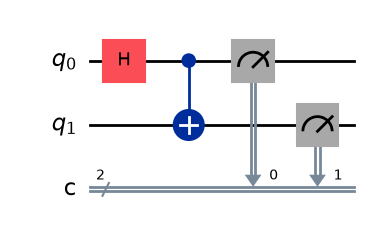

In [2]:
# Create a circuit with exactly 2 qubits and 2 classical bits
qc_original = QuantumCircuit(2, 2)

# Apply Hadamard gate to the first qubit
qc_original.h(0)

# Apply CNOT gate
qc_original.cx(0, 1)

# Measure both qubits
qc_original.measure([0, 1], [0, 1])

# Display the original circuit
print("Original Bell-State Circuit:")
display(qc_original.draw("mpl"))

In [3]:
# Create the simulator
simulator = AerSimulator()

# Execute the original circuit for 100 shots
job_original = simulator.run(qc_original, shots=100)

# Get measurement results
result_original = job_original.result()
counts_original = result_original.get_counts()

# Display results
print("Original Circuit Results:")
print(counts_original)

Original Circuit Results:
{'00': 56, '11': 44}


In [4]:
print(counts_original)

{'00': 56, '11': 44}


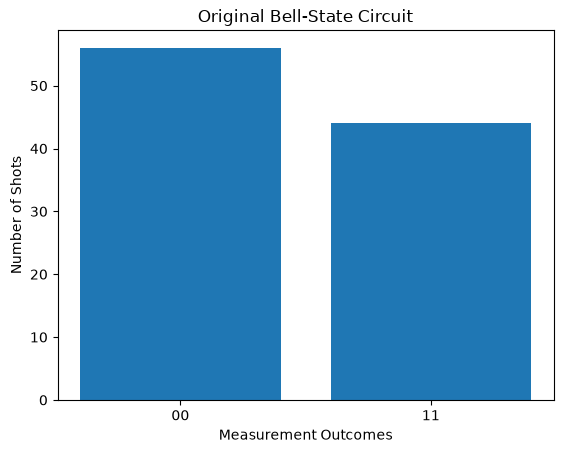

In [5]:
%matplotlib inline

import matplotlib.pyplot as plt

# Get measurement outcomes and counts
labels = list(counts_original.keys())
values = list(counts_original.values())

# Draw histogram
plt.bar(labels, values)

plt.xlabel("Measurement Outcomes")
plt.ylabel("Number of Shots")
plt.title("Original Bell-State Circuit")
plt.show()

In [10]:
from qiskit import QuantumCircuit

# Define a modified circuit
qc_modified = QuantumCircuit(2, 2)
qc_modified.h(0)
qc_modified.cx(0, 1)
qc_modified.measure([0,1], [0,1])


In [11]:
from qiskit_aer import AerSimulator

simulator = AerSimulator()
job_modified = simulator.run(qc_modified, shots=100)
result_modified = job_modified.result()
counts_modified = result_modified.get_counts(qc_modified)
print(counts_modified)


{'11': 50, '00': 50}


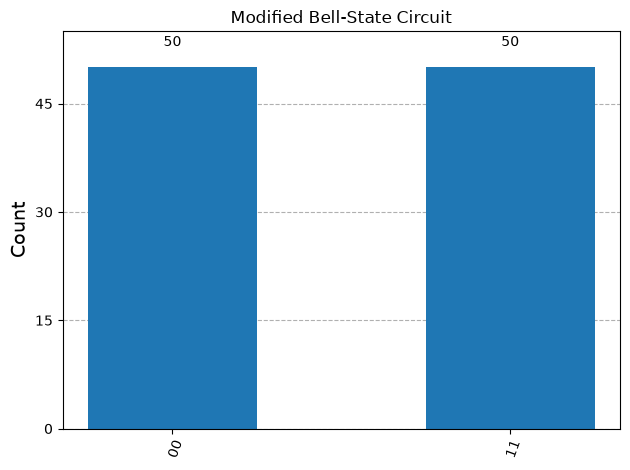

In [12]:
plot_histogram(
    counts_modified,
    title="Modified Bell-State Circuit"
)

plt.show()

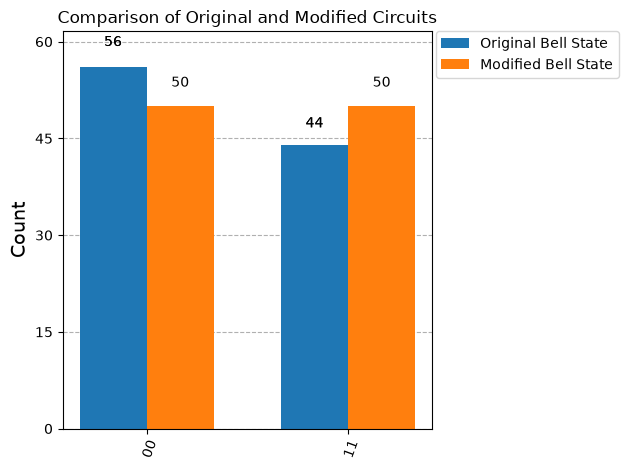

In [13]:
plot_histogram(
    [counts_original, counts_modified],
    legend=["Original Bell State", "Modified Bell State"],
    title="Comparison of Original and Modified Circuits"
)

plt.show()

Explanation

The original Bell-state circuit uses a Hadamard gate followed by a CNOT gate. It creates an entangled state in which the two qubits produce the same measurement outcomes. Therefore, the outcomes 00 and 11 occur with approximately equal probabilities.

In the modified circuit, an X gate is applied to qubit 0 after the CNOT gate. This flips the measurement result of the first qubit and changes the correlated outcomes from 00 and 11 to 01 and 10.

The original and modified circuits are executed for 100 shots, and their measurement results are compared using histograms. The experiment demonstrates how adding a single quantum gate can change the relationship between two qubits' measurement outcomes.